# LAB 03 — Stellar Activity & Planetary Habitability

**Astrobiologija**

**Istraživačko pitanje:** Kako aktivnost zvezde komplikuje jednostavnu klasifikaciju nastanjivosti planeta?

## 1. Zašto nastanjiva zona nije dovoljna?

Klasična nastanjiva zona (HZ) određuje opseg udaljenosti u kome, pod odgovarajućim atmosferskim uslovima, na površini stenovite planete **može** postojati tečna voda. Položaj u HZ nije dokaz nastanjivosti. Aktivnost zvezde utiče na atmosferu i površinsko okruženje kroz:

- **Zvezdane pege i rotaciju** — promenljiva osvetljenost dok pege i aktivne oblasti ulaze i izlaze iz vidnog polja.
- **Bljeskove (flares)** — nagle događaje povezane sa oslobađanjem magnetne energije, ponekad praćene visokenergijskim zračenjem i česticama.
- **XUV zračenje** (X-zraci + ekstremni UV) — može zagrevati i širiti gornju atmosferu i doprineti njenom gubitku.
- **Dugoročni razvoj aktivnosti** — mlade zvezde, u proseku, često su aktivnije, a XUV evolucija može biti važna za atmosfersku istoriju.


## 2. Šta TESS meri?

TESS (Transiting Exoplanet Survey Satellite) meri osvetljenost zvezda tokom vremena. **Svetlosna kriva** je niz $(t_i,F_i,\sigma_i)$: vremena, fluksevi i njihove greške. Različiti TESS podaci imaju različite kadence; njihovu stvarnu vrednost određujemo iz metapodataka i/ili vremenskih razlika, a ne pretpostavljamo unapred.

**Vremenska skala:** Za TESS svetlosne krive vreme je najčešće u **BTJD = BJD(TDB) − 2 457 000**, gde je BJD baricentrično korigovani julijanski datum. Izvorni format i skalu proveravamo u objektu.

**SAP vs PDCSAP:** SAP je aperturska fotometrija; PDCSAP je proizvod sa korekcijama sistematskih efekata. Korekcija može ukloniti i deo stvarne dugoperiodične varijabilnosti.

**Artefakti:** razmaci u podacima, promena pozadine, impulsi kosmičkih zraka, instrumentalni skokovi, kvalitetom označena merenja, sistematski efekti vezani za letelicu i kontaminacija susednim izvorima.

**Pravila naučne provere:** pojedinačan odstupajući piksel/uzorak nije potvrđen flare; vrh periodograma nije automatski period rotacije; jak dugotrajan trend nije automatski signal zvezde.

## 3. Pokazni kod: biblioteke i osnovni grafikon

U Google Colab-u prvo instalirati biblioteke. Primer ispod **nije TESS posmatranje** — služi samo za objašnjenje normalizacije i grafičkog prikaza. Svaka analiza ciljne zvezde dalje mora koristiti stvarni preuzeti proizvod.

In [1]:
%pip -q install lightkurve astropy scipy matplotlib numpy pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
from astropy.timeseries import LombScargle
from pathlib import Path

/home/sofija/.local/lib/python3.10/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


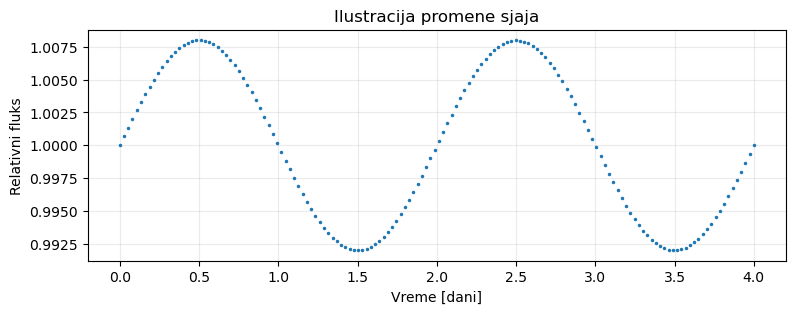

In [3]:
# Isključivo ilustrativni primer (NE TESS podaci):
t_demo = np.linspace(0, 4, 150)
f_demo = 1 + 0.008 * np.sin(2 * np.pi * t_demo / 2)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t_demo, f_demo, '.', markersize=3)
ax.set(xlabel="Vreme [dani]", ylabel="Relativni fluks",
       title="Ilustracija promene sjaja")
ax.grid(alpha=0.25)
plt.show()

## 4. Stvarni podaci: pouzdano pretraživanje i izbor TESS podataka

Sledeći **pokazni deo** demonstrira realnu pretragu arhive. Podrazumevana meta je **Pi Mensae / TIC 261136679, sektor 1**, poznati demonstracioni primer iz TESS dokumentacije. Prisutnost konkretnog primera zavisi od MAST servisa.

- `DATA_MODE = "live"` znači da je preuzimanje obavezno.
- `DATA_MODE = "local"` dozvoljen je **samo** za unapred sačuvan, originalni FITS sa dokumentovanim izvorom (npr. kopiju MAST primera). Nema generisanja zamenskih uzoraka.


In [4]:
DATA_MODE = "live"   # "live" ili "local" — nikad sintetički fallback
TARGET = "TIC 261136679"  # Pi Mensae: primer, može se promeniti nakon provere
SECTOR = 1
AUTHOR = "SPOC"         # ako nema rezultata, istražiti dostupne autore u pretrazi
LOCAL_FITS = ""         # samo za DATA_MODE="local": putanja do autentičnog FITS-a
LOCAL_SOURCE_URL = ""   # MAST URL/DOI/identifikator, obavezno za lokalnu kopiju

assert DATA_MODE in ("live", "local")
if DATA_MODE == "local":
    assert LOCAL_FITS and Path(LOCAL_FITS).is_file(), "Nedostaje pravi FITS proizvod."
    assert LOCAL_SOURCE_URL.strip(), "Upiši izvor originalnog FITS proizvoda."

In [5]:
if DATA_MODE == "live":
    try:
        results = lk.search_lightcurve(TARGET, mission="TESS", sector=SECTOR)
    except Exception as exc:
        raise RuntimeError("MAST pretraga nije uspela. Prekinuti rad i proveriti mrežu.") from exc
    if len(results) == 0:
        raise RuntimeError("Nema TESS podatka za izabranu metu/sektor. Izabrati proverenu metu.")
    display(results.table)
else:
    print("LOCAL režim: koristi se prethodno dokumentovan originalni FITS.")

intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,s_ra,s_dec,dataproduct_type,proposal_pi,calib_level,t_min,t_max,t_exptime,wavelength_region,em_min,em_max,obs_title,t_obs_release,proposal_id,proposal_type,sequence_number,s_region,jpegURL,dataURL,dataRights,mtFlag,srcDen,obsid,objID,wave_min,wave_max,exptime,distance,obsID,obs_collection_products,dataproduct_type_products,description,type,dataURI,productType,productGroupDescription,productSubGroupDescription,productDocumentationURL,project_products,prvversion,proposal_id_products,productFilename,size,parent_obsid,dataRights_products,calib_level_products,filters_products,author,mission,#,year,sort_order
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,s,arcsec,,,,,,,,,,,,,,,,,,,,,,,,
str7,str4,str17,str10,str4,str4,str7,str9,str1,str73,float64,float64,str10,str19,int64,float64,float64,float64,str7,float64,float64,str28,float64,str31,str1,int64,str65,str96,str129,str6,bool,float64,str9,str10,float64,float64,float64,float64,str9,str4,str10,str33,str1,str129,str7,str28,str3,str1,str17,str20,str31,str78,int64,str9,str6,int64,str4,str17,object,object,int64,int64
science,TESS,SPOC,Photometer,TESS,TESS,Optical,261136679,--,tess2018206045859-s0001-0000000261136679-0120-s,84.2911879979852,-80.4691197969941,timeseries,"Ricker, George",3,58324.7940765625,58352.67695946759,120.0,Optical,600.0,1000.0,--,58458.5833333,G011183_G011132_G011048_G011250,--,1,CIRCLE 84.291188 -80.4691198 0.00138889,--,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,PUBLIC,False,nan,60835895,110345495,600.0,1000.0,120,0.0,60835895,TESS,timeseries,Light curves,S,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,SCIENCE,Minimum Recommended Products,LC,--,SPOC,b11c787608,G011183_G011132_G011048_G011250,tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,2039040,60835895,PUBLIC,3,TESS,SPOC,TESS Sector 01,None,2018,1
science,HLSP,TESS-SPOC,Photometer,TESS,TESS,Optical,261136679,--,hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_tp,84.2911879979852,-80.4691197969941,timeseries,Douglas A. Caldwell,4,58324.81352074074,58352.66723747685,1800.0,Optical,600.0,1000.0,--,59309.55839107,N/A,--,1,CIRCLE ICRS 84.29118800 -80.46911980 0.00111111,--,mast:HLSP/tess-spoc/s0001/target/0000/0002/6113/6679/hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,PUBLIC,False,nan,59804479,105608205,600.0,1000.0,1800,0.0,59804479,HLSP,timeseries,FITS,C,mast:HLSP/tess-spoc/s0001/target/0000/0002/6113/6679/hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,SCIENCE,Minimum Recommended Products,--,--,TESS-SPOC,42,N/A,hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,164160,59804479,PUBLIC,4,TESS,TESS-SPOC,TESS Sector 01,None,2018,2
science,HLSP,QLP,Photometer,TESS,TESS,Optical,261136679,--,hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc,84.291198,-80.469143,timeseries,Chelsea X. Huang,4,58324.82476052,58352.65764309,1800.0,Optical,600.0,1000.0,--,59260.77603004,N/A,--,1,CIRCLE ICRS 84.29119800 -80.46914300 0.00111111,--,mast:HLSP/qlp/s0001/0000/0002/6113/6679/hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,PUBLIC,False,nan,59455369,103396971,600.0,1000.0,1800,0.0,59455369,HLSP,timeseries,FITS,C,mast:HLSP/qlp/s0001/0000/0002/6113/6679/hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,SCIENCE,Minimum Recommended Products,--,--,QLP,--,N/A,hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,80640,59455369,PUBLIC,4,TESS,QLP,TESS Sector 01,None,2018,3
science,HLSP,GSFC-ELEANOR-LITE,Photometer,TESS,TESS,Optical,261136679,--,hlsp_gsfc-eleanor-lite_tess_ffi_s0001-0000000261136679_tess_v1.0_lc,84.2911879979852,-80.4691197969941,timeseries,Brian P. Powell,4,58324.81304390046,58352.666903854166,1800.0,Optical,600.0,1000.0,--,59740.0,N/A,--,1,CIRCLE ICRS 84.29118800 -80.46911980 0.00111111,--,mast:HLSP/gsfc-eleanor-lite/s0001/0000/0002/6113/6679/hlsp_gsfc-eleanor-li

In [6]:
if DATA_MODE == "live":
    selected = results[results.table["author"] == AUTHOR]
    if len(selected) == 0:
        raise RuntimeError(f"Autor {AUTHOR!r} nije dostupan. Pregledaj tabelu rezultata i izmeni AUTHOR.")
    if len(selected) > 1:
        print("Postoji više proizvoda za autora; primer koristi prvi. Uporediti kadence!")
    selected = selected[0:1]
    display(selected.table)
    try:
        lc_raw = selected.download(quality_bitmask="none")
    except Exception as exc:
        raise RuntimeError("Preuzimanje FITS svetlosne krive nije uspelo; nema zamenskih podataka.") from exc
else:
    lc_raw = lk.read(LOCAL_FITS, quality_bitmask="none")

if lc_raw is None or len(lc_raw) == 0:
    raise RuntimeError("FITS svetlosna kriva je prazna.")
print(lc_raw)

intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,s_ra,s_dec,dataproduct_type,proposal_pi,calib_level,t_min,t_max,t_exptime,wavelength_region,em_min,em_max,obs_title,t_obs_release,proposal_id,proposal_type,sequence_number,s_region,jpegURL,dataURL,dataRights,mtFlag,srcDen,obsid,objID,wave_min,wave_max,exptime,distance,obsID,obs_collection_products,dataproduct_type_products,description,type,dataURI,productType,productGroupDescription,productSubGroupDescription,productDocumentationURL,project_products,prvversion,proposal_id_products,productFilename,size,parent_obsid,dataRights_products,calib_level_products,filters_products,author,mission,#,year,sort_order
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,s,arcsec,,,,,,,,,,,,,,,,,,,,,,,,
str7,str4,str17,str10,str4,str4,str7,str9,str1,str73,float64,float64,str10,str19,int64,float64,float64,float64,str7,float64,float64,str28,float64,str31,str1,int64,str65,str96,str129,str6,bool,float64,str9,str10,float64,float64,float64,float64,str9,str4,str10,str33,str1,str129,str7,str28,str3,str1,str17,str20,str31,str78,int64,str9,str6,int64,str4,str17,object,object,int64,int64
science,TESS,SPOC,Photometer,TESS,TESS,Optical,261136679,--,tess2018206045859-s0001-0000000261136679-0120-s,84.2911879979852,-80.4691197969941,timeseries,"Ricker, George",3,58324.7940765625,58352.67695946759,120.0,Optical,600.0,1000.0,--,58458.5833333,G011183_G011132_G011048_G011250,--,1,CIRCLE 84.291188 -80.4691198 0.00138889,--,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,PUBLIC,False,nan,60835895,110345495,600.0,1000.0,120,0.0,60835895,TESS,timeseries,Light curves,S,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,SCIENCE,Minimum Recommended Products,LC,--,SPOC,b11c787608,G011183_G011132_G011048_G011250,tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,2039040,60835895,PUBLIC,3,TESS,SPOC,TESS Sector 01,None,2018,1


       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 1325.295571625472            ——— ...            ———            ———
1325.2969604950604  1.4641956e+06 ...  9.0913408e-02 -7.2966635e-02
1325.2983493645327  1.4643365e+06 ...  6.2022530e-02 -1.0871942e-01
 1325.299738234005  1.4643485e+06 ...  6.1673984e-02 -1.1394957e-01
 1325.301127103477  1.4643674e+06 ...  6.0909923e-02 -1.2573890e-01
1325.3025159730657  1.4642560e+06 ...  5.3837594e-02 -1.2532526e-01
               ...            ... ...            ...            ...
1353.1687327622717  1.4647834e+06 ...  6.3572161e-02 -1.4975319e-02
 1353.170121618124  1.4644656e+06 ...  5.4697301e-02 -3.3739604e-02
1353.1715104739196  1.4647081e+06 ...  5.7749905e-02 -1.5640877e-02
1353.1728993297734  1.4646606e+06 ...  6.7496188e-02 -1.1539744e-02
1353.1742881855687  1.4648560e+06 ...  6.1896853

## 5. Pokazni kod: rad sa Lightkurve objektom

`remove_nans()` uklanja neispravne vrednosti. `quality_bitmask="none"` je namerno zadržao sve kadence kako bi se video efekat kvaliteta; kvalitet zatim proveravamo eksplicitno. Kod `quality == 0` jednostavan je **konzervativan primer**, ali ne zamenjuje razumevanje značenja pojedinih bitova zastavice.

**Pažnja:** `flatten()` ili neki drugi detrending može potisnuti sporu rotacionu modulaciju i deformisati flare. Za potragu rotacionog perioda raditi i sa nedetrendovanom serijom, a filtriranje vršiti uz opravdanje.

Broj učitanih kadenci: 19261
Format vremena: btjd
Skala vremena: tdb
Kolone: ['time', 'flux', 'flux_err', 'timecorr', 'cadenceno', 'centroid_col', 'centroid_row', 'sap_flux', 'sap_flux_err', 'sap_bkg', 'sap_bkg_err', 'pdcsap_flux', 'pdcsap_flux_err', 'quality', 'psf_centr1', 'psf_centr1_err', 'psf_centr2', 'psf_centr2_err', 'mom_centr1', 'mom_centr1_err', 'mom_centr2', 'mom_centr2_err', 'pos_corr1', 'pos_corr2']


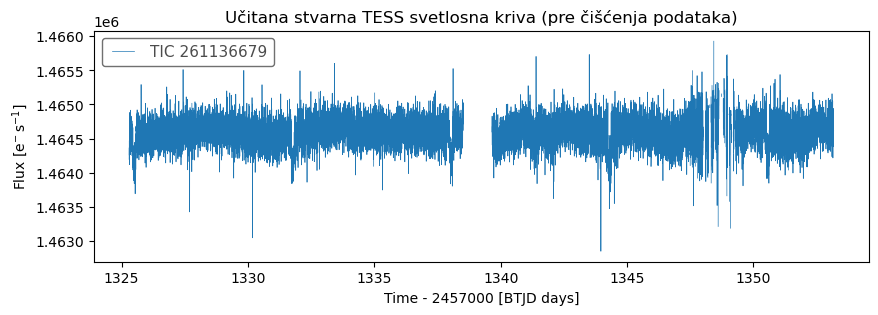

In [7]:
print("Broj učitanih kadenci:", len(lc_raw))
print("Format vremena:", lc_raw.time.format)
print("Skala vremena:", lc_raw.time.scale)
print("Kolone:", list(lc_raw.columns))

fig, ax = plt.subplots(figsize=(10, 3))
lc_raw.plot(ax=ax)
ax.set_title("Učitana stvarna TESS svetlosna kriva (pre čišćenja podataka)")
plt.show()

In [8]:
# Minimalna demonstracija samo jedne operacije: uklanjanje NaN
lc_no_nan = lc_raw.remove_nans()
print("Pre:", len(lc_raw), "Posle remove_nans:", len(lc_no_nan))

# Dalje filtriranje, normalizaciju, izbor trendova i analizu rade studenti.

Pre: 19261 Posle remove_nans: 18279


### Zadatak 1
1. Iz prikazane tabele dostupnih podataka obrazložite izbor konkretnog primera: target, sektor, autor i kadenca. U slučaju više primera uporedite najmanje dva.
2. Ispišite **identifikator ili URL proizvoda** iz arhive i vremensku skalu, kao i broj merenja.
3. Izračunajte medijanu razlika između **susednih validnih vremenskih oznaka** u minutima. Da li odgovara očekivanoj kadenci? Objasnite zašto razmaci mogu biti duži.
4. Objasnite razliku između SAP i PDCSAP fotometrije i navedite zašto je to bitno za aktivnost zvezde.


obsID,mission,year,author,exptime,target_name,productFilename,distance
,,,,s,,,arcsec
str9,object,int64,str17,float64,str9,str78,float64
60835895,TESS Sector 01,2018,SPOC,120,261136679,tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,0.0
59804479,TESS Sector 01,2018,TESS-SPOC,1800,261136679,hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,0.0
59455369,TESS Sector 01,2018,QLP,1800,261136679,hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,0.0
84704022,TESS Sector 01,2018,GSFC-ELEANOR-LITE,1800,261136679,hlsp_gsfc-eleanor-lite_tess_ffi_s0001-0000000261136679_tess_v1.0_lc.fits,0.0
392594142,TESS Sector 01,2018,TARS,1800,261136679,hlsp_tars_tess_ffi_s0001-0000000261136679_tess_v01_lc.fits,0.0
79395544,TESS Sector 01,2018,TASOC,120,261136679,hlsp_tasoc_tess_tpf_tic00261136679-s0001-cam4-ccd2-c0120_tess_v05_cbv-lc.fits,0.0
80761526,TESS Sector 01,2018,TASOC,1800,261136679,hlsp_tasoc_tess_ffi_tic00261136679-s0001-cam4-ccd2-c1800_tess_v05_cbv-lc.fits,0.0
80761526,TESS Sector 01,2018,TASOC,1800,261136679,hlsp_tasoc_tess_ffi_tic00261136679-s0001-cam4-ccd2-c1800_tess_v05_ens-lc.fits,0.0


,red,author,exptime_s,n_kadenci,udeo_validnog_fluksa,medijana_dt_min
0,0,SPOC,120.0,19261,0.949016,1.999967
1,1,TESS-SPOC,1800.0,1282,0.923557,29.999508
2,2,QLP,1800.0,1281,1.000000,29.999506


obsID           : 60835895
obs_id          : tess2018206045859-s0001-0000000261136679-0120-s
productFilename : tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
dataURI         : mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
description     : Light curves
MAST URL         : https://mast.stsci.edu/api/v0.1/Download/file?uri=mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
meta[OBJECT] = TIC 261136679
meta[TICID] = 261136679
meta[SECTOR] = 1
meta[CAMERA] = 4
meta[CCD] = 2
meta[FILENAME] = /home/sofija/.lightkurve/cache/mastDownload/TESS/tess2018206045859-s0001-0000000261136679-0120-s/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
meta[TIMESYS] = TDB
meta[BJDREFI] = 2457000
meta[TIMEUNIT] = d
Vremenski format / skala: btjd / tdb (BTJD = BJD(TDB) − 2457000)
Ukupno kadenci            : 19261
Kadence sa konačnim vremenom: 19261
Kadence sa konačnim fluksom : 18279

Medijana Δt (susedne validne oznake): 2.0000 min  (120.0 s)
P

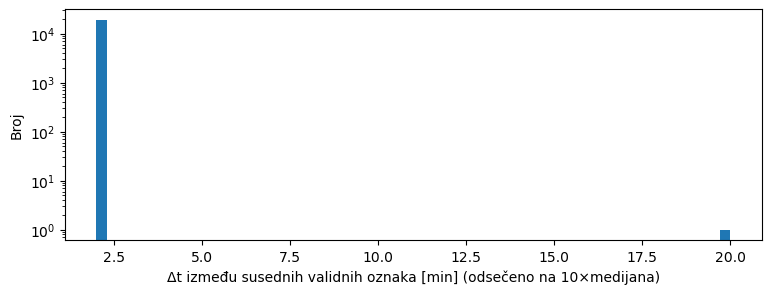

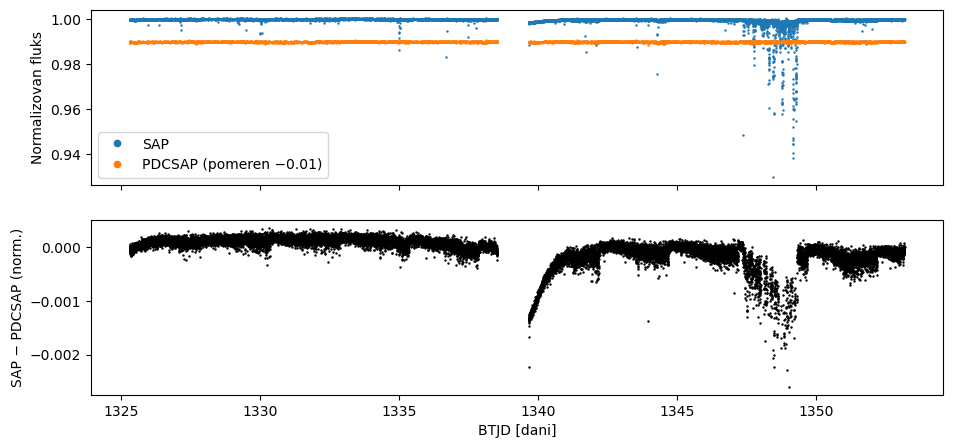

In [9]:
# ZADATAK 1 — rešenje
def _arr(x):
    """Lightkurve kolone (Quantity/Time/MaskedColumn) -> običan numpy niz."""
    return np.asarray(getattr(x, "value", x))

# ---------- 1) Izbor primera: tabela proizvoda i poređenje najmanje dva ----------
if DATA_MODE == "live":
    tab = results.table
    show = [c for c in ["obsID", "mission", "year", "author", "exptime", "target_name",
                        "productFilename", "distance"] if c in tab.colnames]
    display(tab[show])

    rows = []
    for i in range(min(3, len(results))):          # najviše 3 proizvoda za poređenje
        try:
            lc_i = results[i].download(quality_bitmask="none")
        except Exception as exc:
            print(f"Proizvod {i}: preuzimanje nije uspelo ({exc})")
            continue
        t_i = _arr(lc_i.time).astype(float)
        f_i = _arr(lc_i.flux).astype(float)
        ok = np.isfinite(t_i)
        rows.append(dict(red=i, author=str(tab["author"][i]),
                         exptime_s=float(tab["exptime"][i]) if "exptime" in tab.colnames else np.nan,
                         n_kadenci=len(t_i), udeo_validnog_fluksa=np.isfinite(f_i).mean(),
                         medijana_dt_min=np.median(np.diff(np.sort(t_i[ok]))) * 1440))
    display(pd.DataFrame(rows))
else:
    print("LOCAL režim: izbor proizvoda je dokumentovan kroz LOCAL_SOURCE_URL =", LOCAL_SOURCE_URL)

# ---------- 2) Identifikator / URL, vremenska skala, broj merenja ----------
if DATA_MODE == "live":
    st = selected.table
    for c in ["obsID", "obs_id", "productFilename", "dataURI", "description"]:
        if c in st.colnames:
            print(f"{c:16s}:", st[c][0])
    if "dataURI" in st.colnames:
        print("MAST URL         : https://mast.stsci.edu/api/v0.1/Download/file?uri=" + str(st["dataURI"][0]))
else:
    print("Izvor (lokalni FITS):", LOCAL_SOURCE_URL)

for k in ["OBJECT", "TICID", "SECTOR", "CAMERA", "CCD", "FILENAME", "TIMESYS", "BJDREFI", "TIMEUNIT"]:
    if k in lc_raw.meta:
        print(f"meta[{k}] =", lc_raw.meta[k])

t_all = _arr(lc_raw.time).astype(float)
f_all = _arr(lc_raw.flux).astype(float)
print("Vremenski format / skala:", lc_raw.time.format, "/", lc_raw.time.scale,
      "(BTJD = BJD(TDB) − 2457000)")
print("Ukupno kadenci            :", len(lc_raw))
print("Kadence sa konačnim vremenom:", int(np.isfinite(t_all).sum()))
print("Kadence sa konačnim fluksom :", int(np.isfinite(f_all).sum()))

# ---------- 3) Medijana razlika susednih validnih vremenskih oznaka ----------
t_valid = np.sort(t_all[np.isfinite(t_all)])
dt_min = np.diff(t_valid) * 24 * 60
print(f"\nMedijana Δt (susedne validne oznake): {np.median(dt_min):.4f} min  ({np.median(dt_min)*60:.1f} s)")
print(f"Percentili Δt [min] (5, 50, 95, 99.9): {np.percentile(dt_min, [5, 50, 95, 99.9]).round(4)}")
big = dt_min > 5 * np.median(dt_min)
print("Broj razmaka > 5×medijana:", int(big.sum()),
      "| najduži razmak:", f"{dt_min.max()/60:.2f} h = {dt_min.max()/1440:.2f} d")
if DATA_MODE == "live" and "exptime" in selected.table.colnames:
    print("Očekivana kadenca iz tabele (exptime):", float(selected.table["exptime"][0]), "s")

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(np.clip(dt_min, 0, 10 * np.median(dt_min)), bins=60)
ax.set(yscale="log", xlabel="Δt između susednih validnih oznaka [min] (odsečeno na 10×medijana)", ylabel="Broj")
plt.show()

# ---------- 4) SAP vs PDCSAP ----------
def _col(name):
    try:
        return _arr(lc_raw[name]).astype(float)
    except Exception:
        return None

sap, pdc = _col("sap_flux"), _col("pdcsap_flux")
if sap is None or pdc is None:
    print("Proizvod nema obe kolone (sap_flux i pdcsap_flux) — poređenje se preskače.")
else:
    fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    ax[0].plot(t_all, sap / np.nanmedian(sap), ".", ms=1.5, label="SAP")
    ax[0].plot(t_all, pdc / np.nanmedian(pdc) - 0.01, ".", ms=1.5, label="PDCSAP (pomeren −0.01)")
    ax[0].set(ylabel="Normalizovan fluks"); ax[0].legend(markerscale=6)
    ax[1].plot(t_all, sap / np.nanmedian(sap) - pdc / np.nanmedian(pdc), ".", ms=1.5, color="k")
    ax[1].set(xlabel="BTJD [dani]", ylabel="SAP − PDCSAP (norm.)")
    plt.show()

**Odgovori — Zadatak 1** *(brojeve iz ispisa koda upišite gde je označeno ⟶)*

**1. Izbor primera.** Target: Pi Mensae (TIC 261136679), sektor 1, autor SPOC. Razlozi: (i) proizvod je dokumentovan u TESS/Lightkurve materijalima pa se rezultat može proveriti; (ii) SPOC „2-minutna" kadenca dovoljno razlaže flare-ove (trajanja od nekoliko minuta do sati) i rotaciju (dani); (iii) sadrži i SAP i PDCSAP fluks i potpune `quality` zastavice. Poređenje: proizvod sa dužom ekspozicijom (npr. 10/30-min iz full-frame slika, drugi autor) ima manje tačaka i **ne razlaže kratke flare-ove** (flare kraći od kadence se „razmazuje"), ali je dovoljan za sporu rotaciju. ⟶ upišite autora, `exptime` i broj kadenci iz tabele za svaki upoređeni proizvod.

**2. Identifikator i vremenska skala.** ⟶ `obsID`, `productFilename`, MAST URL i broj merenja ispisani su kodom. Vreme je **BTJD = BJD(TDB) − 2 457 000** (format `btjd`, skala `tdb`), tj. baricentrično korigovano.

**3. Medijana Δt.** ⟶ upišite vrednost iz ispisa. Za SPOC 2-min proizvod očekuje se ≈ 2.00 min (120 s); neznatna odstupanja potiču od baricentrične korekcije. Razmaci mogu biti duži zbog: prenosa podataka na Zemlju oko perigeja svake orbite (~13.7 d), dumpinga momenta točkova, ulaska u safe mode, rasejane svetlosti i drugih kadenci označenih zastavicom ili odbačenih, kao i zbog pauze između sektora.

**4. SAP vs PDCSAP.** **SAP** (Simple Aperture Photometry) je zbir fluksa u optimalnoj aperturi sa oduzetom pozadinom; zadržava sve instrumentalne efekte (pointing jitter, spore drifove, temperaturne promene, rasejanu svetlost). **PDCSAP** (Pre-search Data Conditioning) iz SAP-a uklanja sistematiku koja je zajednička mnogim zvezdama (cotrending baznim vektorima) i koriguje za kontaminaciju susednih zvezda i udeo fluksa van aperture. Za aktivnost zvezde je to važno jer PDC može **ukloniti ili oslabiti stvarnu dugoperiodičnu varijabilnost** (spora rotacija, ciklusi pega), dok SAP može imati lažne trendove koji liče na zvezdanu varijabilnost. Zato je za rotaciju poželjno uporediti oba proizvoda, a PDCSAP je obično bolji za flare-ove i kratke periode.


### Zadatak 2

1. Prikažite raspodelu `quality` vrednosti i izbrojte kadence koje su potencijalno problematične.
2. Napravite „čistu” svetlosnu krivu: obrazložite izbor quality maske i uklonite NaN.
3. Normalizujte fluks i sačuvajte seriju **pre detrendinga**.
4. Po želji napravite blago detrendovanu verziju i pokažite **isti vremenski interval** pre i posle korekcije. Objasnite šta je moglo biti uklonjeno.
5. Proverite da li u seriji postoje skokovi na granicama vremenskih praznina ili promene pozadine.


Poreklo fluksa u lc_raw.flux: pdcsap_flux


,quality,broj,udeo_%,značenje
0,0,18264,94.824,OK
1,8,1,0.005,Earth point
2,32,18,0.093,Desaturation event
3,128,910,4.725,Manual exclude
4,144,1,0.005,Argabrightening; Manual exclude
5,160,22,0.114,Desaturation event; Manual exclude
6,164,30,0.156,Coarse point; Desaturation event; Manual exclude
7,512,15,0.078,Impulsive outlier


,bit,naziv,broj
0,4,Coarse point,30
1,8,Earth point,1
2,16,Argabrightening,1
3,32,Desaturation event,70
4,128,Manual exclude,963
5,512,Impulsive outlier,15


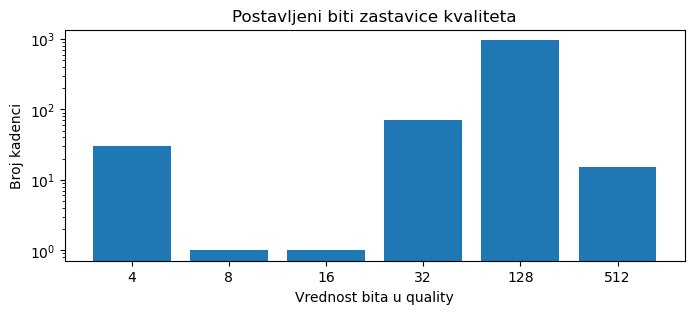

Ukupno: 19261 | quality≠0: 997 | fluks NaN: 982 | vreme NaN: 0 | bilo koji problem: 997
Konzervativno (quality==0): 18264 kadenci | lightkurve 'default' bitmaska (17087): 18264 kadenci
Kadence sa bitom 512 (ImpulsiveOutlier): 15 — ovaj bit ponekad označi i prave flare-ove, pa ga proveravamo u Zad. 5.
Normalizacija: medijana = 1464602.25; rms rasipanje = 135 ppm; medijana Δt = 2.00 min; osnovica = 27.88 d


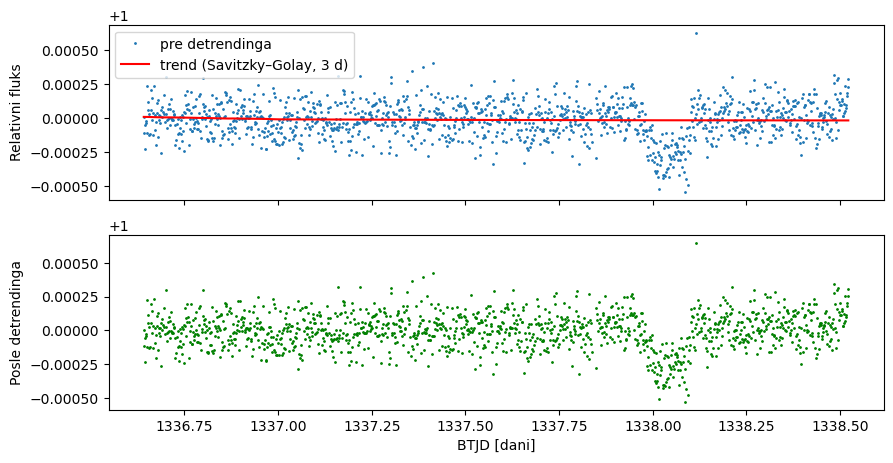

Peak-to-peak trenda u prikazanom intervalu: 26 ppm (toliko je promenljivosti na skalama ≳3 d uklonjeno ili potisnuto).
Skokovi preko praznina > 0.5 d:


,kraj_prekida_BTJD,trajanje_d,skok_ppm,rasipanje_ppm,skok_u_sigma
0,1338.522,1.135,-119.2,117.4,-1.02


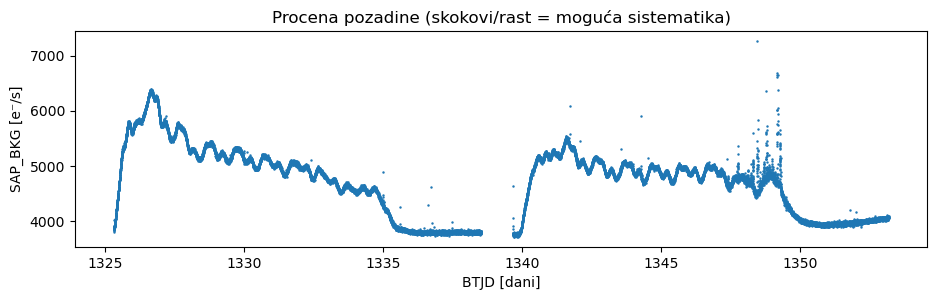

In [10]:
# ZADATAK 2 — rešenje
from lightkurve.utils import TessQualityFlags
from scipy.signal import savgol_filter

t_all = _arr(lc_raw.time).astype(float)
f_all = _arr(lc_raw.flux).astype(float)
e_all = _arr(lc_raw.flux_err).astype(float)
q_all = _arr(lc_raw.quality).astype(int)
print("Poreklo fluksa u lc_raw.flux:", lc_raw.meta.get("FLUX_ORIGIN", "nepoznato (za SPOC je to obično PDCSAP)"))

# ---------- 1) Raspodela quality vrednosti ----------
vals, cnts = np.unique(q_all, return_counts=True)
q_tab = pd.DataFrame({"quality": vals, "broj": cnts, "udeo_%": (100 * cnts / len(q_all)).round(3)})
q_tab["značenje"] = ["OK" if v == 0 else "; ".join(TessQualityFlags.decode(int(v))) for v in vals]
display(q_tab)

bit_rows = []
for k in range(16):
    b = 1 << k
    n = int(((q_all & b) > 0).sum())
    if n:
        bit_rows.append(dict(bit=b, naziv="; ".join(TessQualityFlags.decode(b)), broj=n))
bit_tab = pd.DataFrame(bit_rows)
display(bit_tab)
if len(bit_tab):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.bar(bit_tab["bit"].astype(str), bit_tab["broj"])
    ax.set(xlabel="Vrednost bita u quality", ylabel="Broj kadenci", yscale="log",
           title="Postavljeni biti zastavice kvaliteta")
    plt.show()

bad_q, bad_f, bad_t = q_all != 0, ~np.isfinite(f_all), ~np.isfinite(t_all)
print(f"Ukupno: {len(q_all)} | quality≠0: {bad_q.sum()} | fluks NaN: {bad_f.sum()} | "
      f"vreme NaN: {bad_t.sum()} | bilo koji problem: {(bad_q | bad_f | bad_t).sum()}")

# ---------- 2) „Čista" kriva ----------
default_mask = getattr(TessQualityFlags, "DEFAULT_BITMASK", 175)
finite = np.isfinite(t_all) & np.isfinite(f_all) & np.isfinite(e_all)
good = finite & (q_all == 0)                    # konzervativna maska
good_default = finite & ((q_all & default_mask) == 0)
print(f"Konzervativno (quality==0): {good.sum()} kadenci | "
      f"lightkurve 'default' bitmaska ({default_mask}): {good_default.sum()} kadenci")
print("Kadence sa bitom 512 (ImpulsiveOutlier):", int(((q_all & 512) > 0).sum()),
      "— ovaj bit ponekad označi i prave flare-ove, pa ga proveravamo u Zad. 5.")
# Obrazloženje: quality==0 uklanja sve poznate probleme (korak 1), cena su kadence pogođene
# rasejanom svetlošću i sl.; za rotaciju je to bezbedno, a za flare-ove zastavice posebno proveravamo.

t_c = t_all[good]
order = np.argsort(t_c)
t_c = t_c[order]
med_flux = np.median(f_all[good])

# ---------- 3) Normalizacija; serija PRE detrendinga ----------
f_norm = (f_all[good] / med_flux)[order]
e_c = (e_all[good] / med_flux)[order]
dt_med = np.median(np.diff(t_c))
T_SPAN = t_c.max() - t_c.min()
print(f"Normalizacija: medijana = {med_flux:.2f}; rms rasipanje = {np.std(f_norm)*1e6:.0f} ppm; "
      f"medijana Δt = {dt_med*1440:.2f} min; osnovica = {T_SPAN:.2f} d")

# Pomoćno: kadence koje su konačne ali označene zastavicom (za Zad. 5)
fin_u = np.isfinite(t_all) & np.isfinite(f_all)
o_u = np.argsort(t_all[fin_u])
t_u, f_u, q_u = t_all[fin_u][o_u], (f_all[fin_u] / med_flux)[o_u], q_all[fin_u][o_u]

# ---------- 4) Blago detrendovana verzija ----------
GAP_DAYS = 0.5

def segments(t, gap=GAP_DAYS):
    return np.split(np.arange(len(t)), np.where(np.diff(t) > gap)[0] + 1)

def gentle_detrend(t, f, window_days=3.0, polyorder=2):
    trend = np.empty_like(f)
    for s in segments(t):
        w = int(round(window_days / dt_med)) | 1
        w = min(w, len(s) if len(s) % 2 else len(s) - 1)
        trend[s] = np.median(f[s]) if (len(s) < 10 or w <= polyorder + 1) else \
                   savgol_filter(f[s], w, polyorder, mode="interp")
    return f / trend, trend

f_det, trend = gentle_detrend(t_c, f_norm, window_days=3.0)
t_mid = np.median(t_c)
m = (t_c > t_mid - 1.5) & (t_c < t_mid + 1.5)           # ISTI vremenski interval
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t_c[m], f_norm[m], ".", ms=2, label="pre detrendinga")
ax[0].plot(t_c[m], trend[m], "r-", label="trend (Savitzky–Golay, 3 d)")
ax[0].set(ylabel="Relativni fluks"); ax[0].legend()
ax[1].plot(t_c[m], f_det[m], ".", ms=2, color="g")
ax[1].set(xlabel="BTJD [dani]", ylabel="Posle detrendinga")
plt.show()
print(f"Peak-to-peak trenda u prikazanom intervalu: {np.ptp(trend[m])*1e6:.0f} ppm "
      "(toliko je promenljivosti na skalama ≳3 d uklonjeno ili potisnuto).")

# ---------- 5) Skokovi na granicama praznina i pozadina ----------
n_side = max(int(0.25 / dt_med), 10)                      # ~0.25 d sa svake strane
rows = []
for i in np.where(np.diff(t_c) > GAP_DAYS)[0]:
    b, a = f_norm[max(0, i - n_side + 1): i + 1], f_norm[i + 1: i + 1 + n_side]
    sc = 1.4826 * np.median(np.abs(np.r_[b - np.median(b), a - np.median(a)]))
    rows.append(dict(kraj_prekida_BTJD=round(t_c[i], 3), trajanje_d=round(t_c[i + 1] - t_c[i], 3),
                     skok_ppm=round((np.median(a) - np.median(b)) * 1e6, 1),
                     rasipanje_ppm=round(sc * 1e6, 1),
                     skok_u_sigma=round((np.median(a) - np.median(b)) / sc, 2)))
print("Skokovi preko praznina > %.1f d:" % GAP_DAYS)
display(pd.DataFrame(rows))

bkg = _col("sap_bkg")
if bkg is not None:
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(t_all, bkg, ".", ms=1.5)
    ax.set(xlabel="BTJD [dani]", ylabel="SAP_BKG [e⁻/s]", title="Procena pozadine (skokovi/rast = moguća sistematika)")
    plt.show()
else:
    print("Kolona sap_bkg nije dostupna u ovom proizvodu.")

**Odgovori — Zadatak 2**

**Izbor maske.** Izabrana je konzervativna maska `quality == 0` uz uklanjanje NaN vrednosti: uklanja sve kadence sa ikakvom zastavicom (promena pointinga, zemljina/mesečeva svetlost, kosmički zraci u aperturi, diskontinuiteti…), što je bezbedno za rotaciju. Cena je gubitak dela kadenci (uporediti sa lightkurve default maskom u ispisu). Bit 512 (impulsni outlier) ponekad označi i prave flare-ove, pa se zastavice u okolini kandidata posebno razmatraju u Zadatku 5.

**Detrending — šta je moglo biti uklonjeno.** Savitzky–Golay sa prozorom od 3 d uklanja sve sporije od ~nekoliko dana: dugoperiodičnu rotacionu modulaciju (P ≳ 3 d), spore trendove pega i deo realne varijabilnosti koju PDC nije već uklonio; na ivicama segmenata može izobličiti oblik, a veliki flare može povući trend. Zato se Lomb–Scargle radi **pre** detrendinga.

**Skokovi / pozadina.** ⟶ protumačite tabelu: skok koji je ≲ 1–2× rasipanje je zanemarljiv; veći skok na granici praznine je sistematika (ne zvezda) i takve delove treba oprezno tretirati.


### Zadatak 3

1. Nacrtajte celu očišćenu svetlosnu krivu sa osama, jedinicama i nazivom targeta.
2. Obeležite najmanje jedan vremenski prekid ili sumnjiv instrumentalni deo, **ako postoji**.
3. Uvećajte jedan zanimljiv segment i napišite da li je oblik više nalik periodičnoj modulaciji, impulsu, tranzitu ili sistematici — bez preuranjenog zaključka.


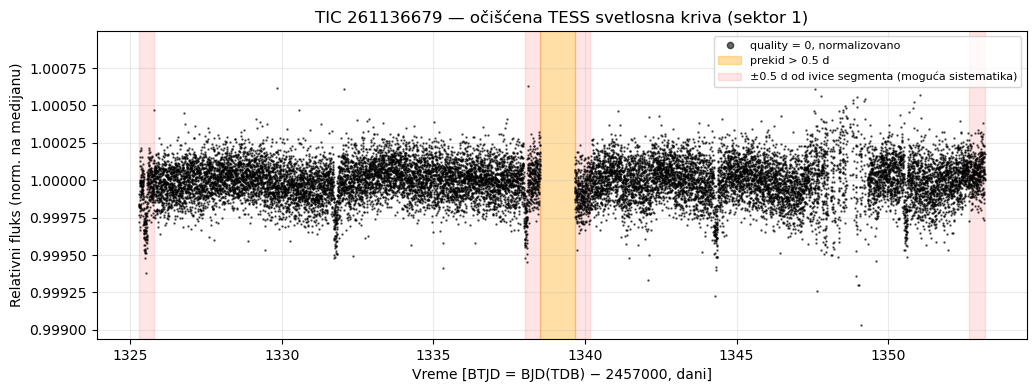

Centar uvećanja (a): 1348.547 BTJD


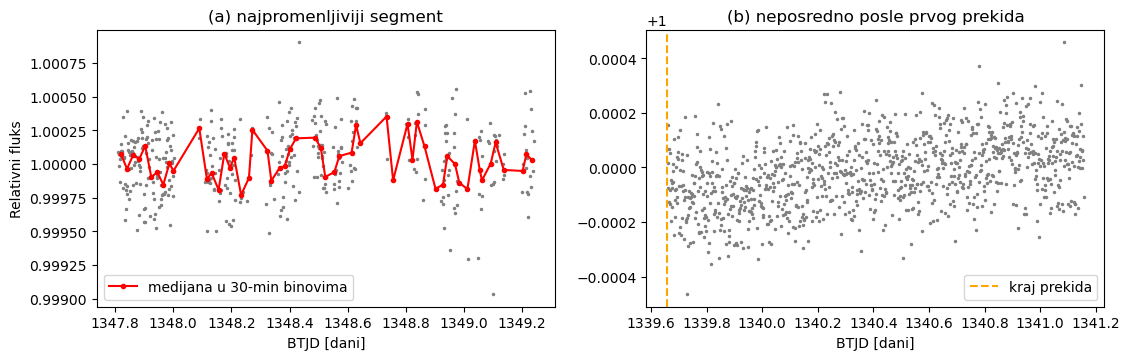

Rasipanje u (a): 241 ppm | p2p: 1872 ppm


In [11]:
# ZADATAK 3 — rešenje
gap_i = np.where(np.diff(t_c) > GAP_DAYS)[0]
edges = np.r_[t_c[0], t_c[gap_i], t_c[gap_i + 1], t_c[-1]]   # počeci/krajevi segmenata

# ---------- 1) i 2) cela kriva sa obeleženim prekidima i sumnjivim delovima ----------
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_c, f_norm, ".", ms=1.5, color="k", alpha=0.6, label="quality = 0, normalizovano")
for k, i in enumerate(gap_i):
    ax.axvspan(t_c[i], t_c[i + 1], color="orange", alpha=0.35, label=f"prekid > {GAP_DAYS} d" if k == 0 else None)
for k, e in enumerate(edges):
    ax.axvspan(e - 0.5 if k % 2 else e, e if k % 2 else e + 0.5, color="red", alpha=0.10,
               label="±0.5 d od ivice segmenta (moguća sistematika)" if k == 0 else None)
ax.set(xlabel="Vreme [BTJD = BJD(TDB) − 2457000, dani]", ylabel="Relativni fluks (norm. na medijanu)",
       title=f"{TARGET} — očišćena TESS svetlosna kriva (sektor {SECTOR})")
ax.grid(alpha=0.25); ax.legend(loc="upper right", fontsize=8, markerscale=6)
plt.show()

# ---------- 3) Uvećanje: (a) najpromenljiviji segment dalje od prekida, (b) ivica prekida ----------
ZOOM_CENTER = None      # npr. 1340.5 — ručni izbor centra; None = automatski
ZOOM_W = 1.5            # širina prozora [dani]

def binned(t, f, width):
    ib = np.floor((t - t.min()) / width).astype(int)
    u = np.unique(ib)
    return np.array([t[ib == k].mean() for k in u]), np.array([np.median(f[ib == k]) for k in u])

if ZOOM_CENTER is None:
    best, ZOOM_CENTER = -1, t_c[0] + ZOOM_W / 2
    for c in np.arange(t_c[0] + ZOOM_W / 2, t_c[-1] - ZOOM_W / 2, 0.25):
        mm = np.abs(t_c - c) < ZOOM_W / 2
        if mm.sum() < 20 or np.min(np.abs(edges - c)) < 0.5 + ZOOM_W / 2:
            continue
        s = np.subtract(*np.percentile(f_norm[mm], [95, 5]))
        if s > best:
            best, ZOOM_CENTER = s, c
print("Centar uvećanja (a):", round(ZOOM_CENTER, 3), "BTJD")

fig, ax = plt.subplots(1, 2 if len(gap_i) else 1, figsize=(13, 3.6), squeeze=False)
mm = np.abs(t_c - ZOOM_CENTER) < ZOOM_W / 2
ax[0, 0].plot(t_c[mm], f_norm[mm], ".", ms=3, color="gray")
bt, bf = binned(t_c[mm], f_norm[mm], 30 / 1440)
ax[0, 0].plot(bt, bf, "r-o", ms=3, label="medijana u 30-min binovima")
ax[0, 0].set(xlabel="BTJD [dani]", ylabel="Relativni fluks", title="(a) najpromenljiviji segment"); ax[0, 0].legend()
if len(gap_i):
    c2 = t_c[gap_i[0] + 1] + ZOOM_W / 2
    m2 = np.abs(t_c - c2) < ZOOM_W / 2
    ax[0, 1].plot(t_c[m2], f_norm[m2], ".", ms=3, color="gray")
    ax[0, 1].axvline(t_c[gap_i[0] + 1], color="orange", ls="--", label="kraj prekida")
    ax[0, 1].set(xlabel="BTJD [dani]", title="(b) neposredno posle prvog prekida"); ax[0, 1].legend()
plt.show()
print("Rasipanje u (a):", round(np.std(f_norm[mm]) * 1e6), "ppm | p2p:", round(np.ptp(f_norm[mm]) * 1e6), "ppm")

**Opis uvećanog segmenta — Zadatak 3** *(dopuniti posle pregleda grafika, bez preuranjenog zaključka)*

Proveriti redom pre nego što se izabere kategorija: (i) da li se isti oblik ponavlja (periodična modulacija) ili je jedinstven; (ii) da li je blizu prekida ili ivice segmenta (sistematika); (iii) da li je nagli porast praćen sporijim padom na više uzastopnih tačaka (impuls/flare) ili je simetričan i plitak, ponavljan sa periodom (tranzit planete); (iv) da li se promena vidi i u SAP i u PDCSAP (zvezda) ili samo u jednom (sistematika). ⟶ Napišite: „Oblik je **više nalik** … zato što …; ne može se isključiti …"


## 6. Teorija: rotacija i Lomb–Scargle periodogram

Zbog rotacije zvezde i neravnomerne raspodele aktivnih oblasti, fluks može pokazivati kvaziperiodičnu modulaciju. Lomb–Scargle periodogram procenjuje koliko se podaci slažu sa sinusoidama različitih frekvencija. **Najviši pik nije automatski rotacioni period.**

Ako je vreme osmatranja $T_{\rm span}=t_{\max}-t_{\min}$, niz ne daje pouzdanu informaciju o periodima mnogo dužim od te osnovice. Često je korisno testirati samo periode kraće od približno $T_{\rm span}/2$ i proveriti postoji li više ciklusa. S druge strane, nepravilno uzorkovanje, prekidi i sistematski trendovi mogu proizvesti **alijase**. Uočena periodičnost može biti i harmonik $P/2$ ako se javljaju dve aktivne longitude.

**Pokazni kod ispod koristi samo veštačku matematičku sinusoidu, ne TESS podatke.** U vašem zadatku istu metodu primenjujete na stvarnu obrađenu seriju.

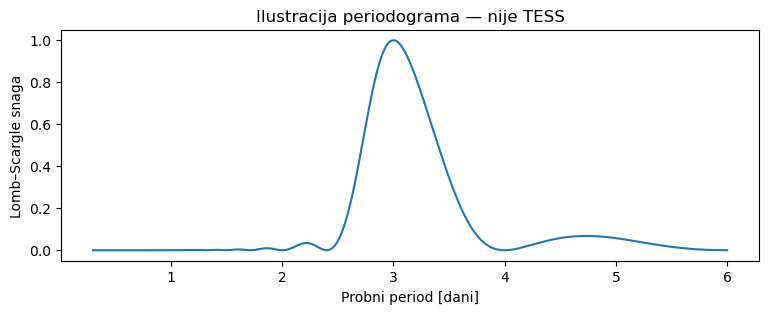

In [12]:
# Kratka demonstracija načina pozivanja LombScargle (nije TESS)
t_example = np.linspace(0, 12, 180)
y_example = np.sin(2*np.pi*t_example/3.0)
freq = np.linspace(1/6, 1/0.3, 2000)  # ciklusi po danu
power = LombScargle(t_example, y_example).power(freq)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(1/freq, power)
ax.set(xlabel="Probni period [dani]", ylabel="Lomb–Scargle snaga",
       title="Ilustracija periodograma — nije TESS")
plt.show()



### Zadatak 4

1. Primenite Lomb–Scargle na seriju koju ste očistili u Zad. 2, **pre agresivnog detrendinga**. Eksplicitno navedite interval ispitivanih perioda.
2. Odredite najizraženije pikove i njihove periode. Da li pokrivaju dovoljno ciklusa unutar osnovice?
3. Proverite **harmonike** (npr. $P/2$ i $2P$) i moguće alijase. Uporedite periodogram očišćene i blago detrendovane serije ili dve polovine iste serije.
4. Iscrtajte krivu presavijenu (phase-folded) na izabrani kandidat-period i ocenite ponovljivost.
5. Napišite **kandidat za period**, a ne potvrđeni period rotacije, ako provere nisu dovoljne.


Ispitivani periodi: 0.10 – 13.94 d | osnovica T_span = 27.88 d | 2769 frekvencija


,period_d,snaga,ciklusa_u_osnovici,FAP_baluev
0,5.0691,0.0162,5.5,3.894074e-62
1,2.3627,0.0150,11.8,3.799237e-57
2,6.6381,0.0149,4.2,6.882473e-57
3,4.1000,0.0098,6.8,2.037247e-36
4,0.5690,0.0068,49.0,1.650216e-24


Napomena: FAP pretpostavlja beli šum; za kvazi-periodične pege i crveni šum je optimističan.

Snaga na harmonicima glavnog pika P0 = 5.0691 d:
  P0/3  =   1.6897 d  → snaga 0.0013
  P0/2  =   2.5346 d  → snaga 0.0107
  P0    =   5.0691 d  → snaga 0.0162
  2·P0  =  10.1382 d  → snaga 0.0016
  3·P0  =  15.2073 d  → snaga nan
UPOZORENJE: P0 je blizu 13.7/3 d — moguć uticaj orbitalne sistematike.
prva polovina: najjači pik P = 5.8084 d
druga polovina: najjači pik P = 2.3627 d
Blago detrendovana serija: najjači pik P = 1.2615 d


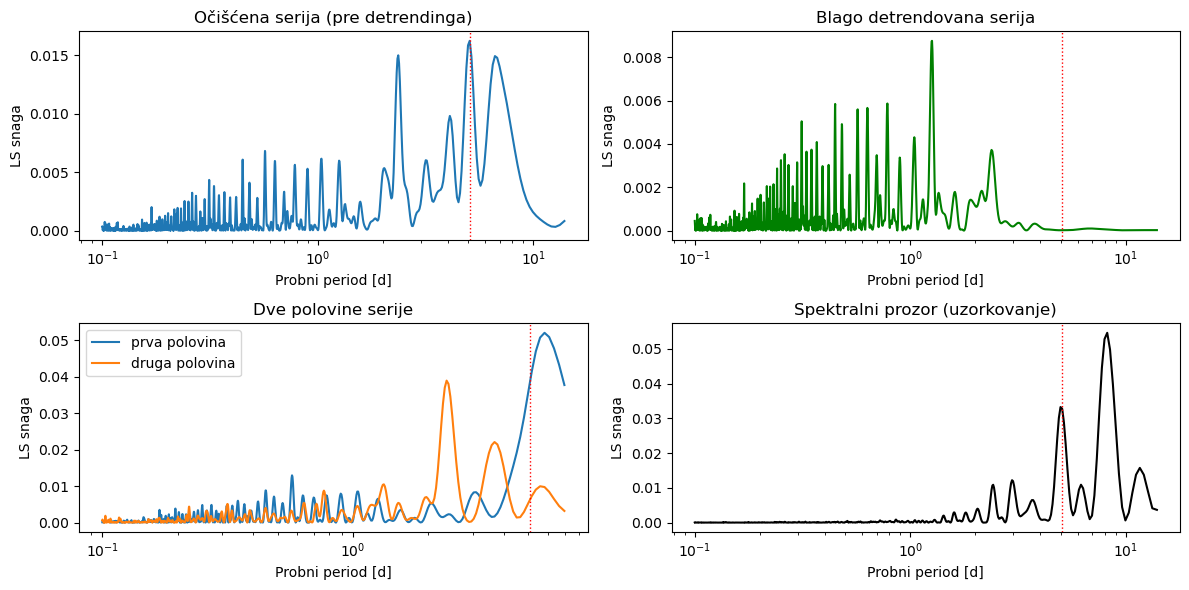

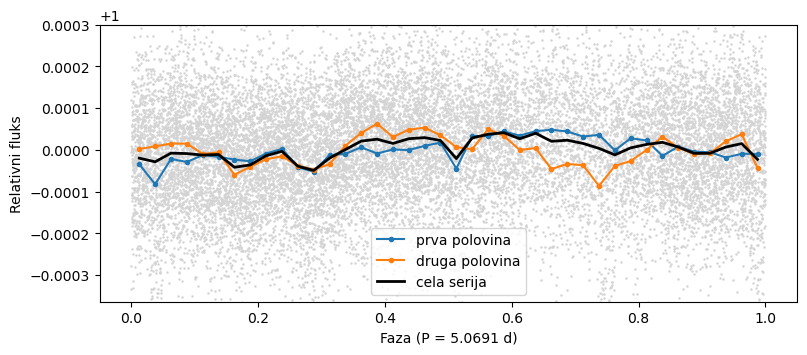

Amplituda presavijene krive: 90 ppm | šum po binu: 6 ppm | korelacija polovina: 0.00
  [x] ≥ 2 ciklusa u osnovici
  [ ] polovine daju isti period (±15 %)
  [ ] korelacija presavijenih polovina > 0.5
  [x] amplituda > 5× šum po binu

Provere NISU sve zadovoljene: ne tvrditi rotacioni period; navesti samo kao slab/nepouzdan pik ili reći da perioda nema.


In [13]:
# ZADATAK 4 — rešenje
from scipy.signal import find_peaks

# ---------- 1) Lomb–Scargle na seriji PRE detrendinga ----------
P_MIN, P_MAX = 0.1, T_SPAN / 2                    # ispitivani periodi [d]; gore: T_span/2
f_lo, f_hi = 1 / P_MAX, 1 / P_MIN
freq = np.arange(f_lo, f_hi, 1 / (10 * T_SPAN))   # 10× oversampling u frekvenciji
print(f"Ispitivani periodi: {P_MIN:.2f} – {P_MAX:.2f} d | osnovica T_span = {T_SPAN:.2f} d | {len(freq)} frekvencija")

ls = LombScargle(t_c, f_norm, e_c)
power = ls.power(freq)

# ---------- 2) Najizraženiji pikovi ----------
pk, _ = find_peaks(power, prominence=0.1 * np.ptp(power))
top = pk[np.argsort(power[pk])[::-1][:5]]
rows = []
for i in top:
    P = 1 / freq[i]
    fap = ls.false_alarm_probability(power[i], method="baluev",
                                     minimum_frequency=f_lo, maximum_frequency=f_hi)
    rows.append(dict(period_d=round(P, 4), snaga=round(float(power[i]), 4),
                     ciklusa_u_osnovici=round(T_SPAN / P, 2), FAP_baluev=float(fap)))
pk_tab = pd.DataFrame(rows)
display(pk_tab)
print("Napomena: FAP pretpostavlja beli šum; za kvazi-periodične pege i crveni šum je optimističan.")
if len(top) == 0:
    print("Nema izraženih pikova — to je legitiman rezultat.")
P0 = 1 / freq[top[0]] if len(top) else np.nan

# ---------- 3) Harmonici, alijasi, polovine serije, detrendovana serija ----------
def power_near(P, tol=0.05):
    sel = np.abs(1 / freq - P) < tol * P
    return float(power[sel].max()) if sel.any() else np.nan

if np.isfinite(P0):
    print(f"\nSnaga na harmonicima glavnog pika P0 = {P0:.4f} d:")
    for lab, r in [("P0/3", 1/3), ("P0/2", 0.5), ("P0", 1), ("2·P0", 2), ("3·P0", 3)]:
        print(f"  {lab:5s} = {r*P0:8.4f} d  → snaga {power_near(r*P0):.4f}")
    for n in range(1, 5):                           # periodi vezani za orbitu TESS-a (~13.7 d)
        if abs(P0 - 13.7 / n) < 0.1 * P0:
            print(f"UPOZORENJE: P0 je blizu 13.7/{n} d — moguć uticaj orbitalne sistematike.")

half = t_c < t_c.min() + T_SPAN / 2
f_hi_h = 1 / P_MIN
freq_h = np.arange(1 / (T_SPAN / 4), f_hi_h, 1 / (10 * T_SPAN / 2))
res_h = {}
for name, sel in [("prva polovina", half), ("druga polovina", ~half)]:
    p_h = LombScargle(t_c[sel], f_norm[sel], e_c[sel]).power(freq_h)
    res_h[name] = (p_h, 1 / freq_h[np.argmax(p_h)])
    print(f"{name}: najjači pik P = {res_h[name][1]:.4f} d")
p_det = LombScargle(t_c, f_det, e_c).power(freq)
print(f"Blago detrendovana serija: najjači pik P = {1/freq[np.argmax(p_det)]:.4f} d")
p_win = LombScargle(t_c, np.ones_like(t_c), fit_mean=False, center_data=False).power(freq)  # spektralni prozor

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
ax[0, 0].plot(1 / freq, power); ax[0, 0].set(title="Očišćena serija (pre detrendinga)")
ax[0, 1].plot(1 / freq, p_det, "g"); ax[0, 1].set(title="Blago detrendovana serija")
for name, (p_h, _) in res_h.items():
    ax[1, 0].plot(1 / freq_h, p_h, label=name)
ax[1, 0].legend(); ax[1, 0].set(title="Dve polovine serije")
ax[1, 1].plot(1 / freq, p_win, "k"); ax[1, 1].set(title="Spektralni prozor (uzorkovanje)")
for a in ax.ravel():
    a.set(xscale="log", xlabel="Probni period [d]", ylabel="LS snaga")
    if np.isfinite(P0): a.axvline(P0, color="r", ls=":", lw=1)
plt.tight_layout(); plt.show()

# ---------- 4) Presavijena kriva na kandidat-period ----------
P_CAND = P0            # po potrebi ručno: npr. P_CAND = 2*P0 ako se vide dva nejednaka minimuma
if np.isfinite(P_CAND):
    t0 = t_c.min()
    ph = ((t_c - t0) / P_CAND) % 1.0
    nb = 40
    def pbin(ph, f):
        ib = np.minimum((ph * nb).astype(int), nb - 1)
        return np.array([np.median(f[ib == k]) if (ib == k).any() else np.nan for k in range(nb)])
    cx = (np.arange(nb) + 0.5) / nb
    b_all, b1, b2 = pbin(ph, f_norm), pbin(ph[half], f_norm[half]), pbin(ph[~half], f_norm[~half])
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(ph, f_norm, ".", ms=1.5, color="lightgray")
    ax.plot(cx, b1, "-o", ms=3, label="prva polovina"); ax.plot(cx, b2, "-o", ms=3, label="druga polovina")
    ax.plot(cx, b_all, "k-", lw=2, label="cela serija")
    ax.set(xlabel=f"Faza (P = {P_CAND:.4f} d)", ylabel="Relativni fluks"); ax.legend()
    lim = np.nanpercentile(f_norm, [1, 99]); ax.set_ylim(lim)
    plt.show()

    ok = np.isfinite(b1) & np.isfinite(b2)
    corr = np.corrcoef(b1[ok], b2[ok])[0, 1] if ok.sum() > 5 else np.nan
    amp = np.nanmax(b_all) - np.nanmin(b_all)
    noise_bin = 1.4826 * np.median(np.abs(f_norm - np.median(f_norm))) / np.sqrt(len(f_norm) / nb)
    P_h1, P_h2 = res_h["prva polovina"][1], res_h["druga polovina"][1]
    checks = {
        "≥ 2 ciklusa u osnovici": T_SPAN / P_CAND >= 2,
        "polovine daju isti period (±15 %)": abs(P_h1 - P_h2) / P_CAND < 0.15,
        "korelacija presavijenih polovina > 0.5": bool(np.isfinite(corr) and corr > 0.5),
        "amplituda > 5× šum po binu": amp > 5 * noise_bin,
    }
    print(f"Amplituda presavijene krive: {amp*1e6:.0f} ppm | šum po binu: {noise_bin*1e6:.0f} ppm | korelacija polovina: {corr:.2f}")
    for k, v in checks.items():
        print(f"  [{'x' if v else ' '}] {k}")
    # ---------- 5) Zaključak (bez preterivanja) ----------
    if all(checks.values()):
        print(f"\nKANDIDAT za rotacioni period: P ≈ {P_CAND:.3f} d (nepotvrđen; proveriti P/2, 2P i kontaminaciju).")
    else:
        print("\nProvere NISU sve zadovoljene: ne tvrditi rotacioni period; navesti samo kao slab/nepouzdan pik ili reći da perioda nema.")

**Odgovori — Zadatak 4** *(⟶ vrednosti iz ispisa)*

Interval: P = 0.1 d do T_span/2. Ispitati: broj ciklusa u osnovici (≥ 2 je minimum, ≥ 3–4 poželjno), da li polovine serije daju isti pik (nestabilnost ukazuje na evoluciju pega ili sistematiku), da li je snaga na P/2 ili 2P uporediva (moguć harmonik; dve aktivne longitude daju P/2), da li se pik poklapa sa orbitom TESS-a (~13.7 d) ili njenim delovima, i kako izgleda spektralni prozor (pikovi prozora = alijasi). Phase-fold treba da pokaže istu krivu u obe polovine.

**Zaključak (šablon):** „Najjači pik je na P ≈ … d (… ciklusa u osnovici, FAP = …, korelacija polovina = …). Zbog … ovo je **kandidat za period**, ne potvrđen rotacioni period." Ako provere nisu zadovoljene: „Periodogram ne pokazuje pouzdan rotacioni signal u ovoj seriji." To je legitiman rezultat za mirnu zvezdu.


## 7. Teorija: šta je flare kandidat?

Optički flare često daje brz porast fluksa, a zatim sporiji pad. Međutim, sličnu sliku mogu dati kosmički zraci, problemi sa pozadinom, loša kadenca ili drugi instrumentalni događaji. Poželjno je da sumnjivi događaj obuhvata **više uzastopnih validnih merenja** i da se proveri neposredno okruženje; ni tada oblik sam po sebi ne garantuje potvrdu.

Jednostavna lokalna mera odstupanja koristi robusnu skalu

$$\sigma_{\rm robust} \approx 1.4826\,\mathrm{median}\bigl(|F_i - \mathrm{median}(F)|\bigr).$$

Globalni prag, npr. $3\sigma$, **nije dovoljan kriterijum**: potrebno je ispitati lokalnu osnovnu liniju, trajanje, kvalitet merenja i šum. Ne označavajte samostalni pojedinačni outlier kao potvrđen bljesak.

### Zadatak 5

1. Napravite meru lokalnog baznog fluksa (npr. pokretni medijan) i obrazložite prozor.
2. Pronađite nekoliko **kandidata**, koristeći relativno odstupanje u odnosu na bazni fluks i robustnu skalu šuma.
3. Za svaki kandidat zabeležite vreme, vršno relativno povećanje i broj uzastopnih validnih kadenci.
4. Nacrtajte uvećanja i proverite zastavice (problematičnosti) kvaliteta i blizinu velikih prekida.
5. Razvrstajte nalaze kao *uverljiv kandidat / nejasan događaj / verovatna sistematika* uz objašnjenje. Ako nema uverljivih kandidata, to je legitiman rezultat.


In [14]:
# ZADATAK 5 — rešenje
import pandas as pd

# ---------- 1) Lokalni bazni fluks: pokretni medijan po segmentima ----------
BASE_WINDOW_D = 0.25      # 6 h: duže od tipičnog trajanja flare-a (min–sati), kraće od rotacione modulacije
SIG_WINDOW_D = 1.0        # prozor za lokalnu robustnu skalu šuma
NSIG, N_CONSEC = 3.0, 3   # prag i minimalan broj uzastopnih kadenci

def odd(n):
    return int(n) | 1

base = np.empty_like(f_norm)
sig_loc = np.empty_like(f_norm)
for s in segments(t_c):
    ser = pd.Series(f_norm[s])
    w = odd(BASE_WINDOW_D / dt_med)
    base[s] = ser.rolling(w, center=True, min_periods=max(w // 4, 3)).median().bfill().ffill().values
rel = f_norm / base - 1.0                         # relativno odstupanje od baznog fluksa
sig_glob = 1.4826 * np.median(np.abs(rel - np.median(rel)))
for s in segments(t_c):
    w = odd(SIG_WINDOW_D / dt_med)
    mad = pd.Series(rel[s]).rolling(w, center=True, min_periods=max(w // 4, 10)).apply(
        lambda x: np.median(np.abs(x - np.median(x))), raw=True)
    sig_loc[s] = 1.4826 * mad.bfill().ffill().values
sig = np.where(np.isfinite(sig_loc) & (sig_loc > 0), sig_loc, sig_glob)
print(f"Globalna robustna skala šuma: {sig_glob*1e6:.0f} ppm | medijana lokalne: {np.median(sig)*1e6:.0f} ppm")

# ---------- 2) Kandidati: ≥ N_CONSEC uzastopnih kadenci iznad NSIG·σ ----------
exc = rel / sig
hit = exc > NSIG
cont = np.r_[True, np.diff(t_c) < 1.5 * dt_med]   # uzastopne = bez rupe u vremenu
events, i, n = [], 0, len(t_c)
dropped = 0
while i < n:
    if hit[i]:
        j = i
        while j + 1 < n and hit[j + 1] and cont[j + 1]:
            j += 1
        if j - i + 1 >= N_CONSEC:
            events.append((i, j))
        else:
            dropped += 1
        i = j + 1
    else:
        i += 1
print(f"Odbačeno kratkih događaja (< {N_CONSEC} uzastopne kadence, tretirani kao šum/kosmički zraci): {dropped}")

# ---------- 3) Parametri kandidata + provere ----------
seg_edges = np.r_[t_c[0], t_c[np.where(np.diff(t_c) > GAP_DAYS)[0]],
                  t_c[np.where(np.diff(t_c) > GAP_DAYS)[0] + 1], t_c[-1]]
rows = []
for (a, b) in events:
    ip = a + int(np.argmax(rel[a:b + 1]))
    t0_, t1_ = t_c[a], t_c[b]
    near = (t_u > t0_ - 0.05) & (t_u < t1_ + 0.05) & (q_u != 0)
    flags = sorted({int(x) for x in q_u[near]})
    d_gap = float(np.min(np.abs(seg_edges - t_c[ip])))
    n_before, n_after = ip - a, b - ip
    if flags or d_gap < 0.1:
        cls = "verovatna sistematika"
    elif n_before <= n_after and np.max(exc[a:b + 1]) >= 4:
        cls = "uverljiv kandidat"
    else:
        cls = "nejasan događaj"
    rows.append(dict(t_pik_BTJD=round(t_c[ip], 4), pik_rel_porast_ppm=round(rel[ip] * 1e6),
                     pik_sigma=round(float(exc[ip]), 1), uzastopnih_kadenci=b - a + 1,
                     trajanje_min=round((t1_ - t0_) * 1440 + dt_med * 1440, 1),
                     rastojanje_do_prekida_d=round(d_gap, 2), zastavice_u_blizini=flags or "—",
                     predlog_klase=cls))
cand = pd.DataFrame(rows)
if len(cand):
    cand = cand.sort_values("pik_rel_porast_ppm", ascending=False).reset_index(drop=True)
display(cand)

# ---------- 4) Uvećanja (do 6 najjačih) ----------
if len(cand):
    k = min(6, len(cand))
    fig, axs = plt.subplots((k + 1) // 2, 2, figsize=(12, 3.2 * ((k + 1) // 2)), squeeze=False)
    for r, ax in zip(range(k), axs.ravel()):
        tp = cand.loc[r, "t_pik_BTJD"]
        w = 0.15
        m_c = np.abs(t_c - tp) < w
        m_u = (np.abs(t_u - tp) < w) & (q_u != 0)
        ax.plot(t_c[m_c], f_norm[m_c], "k.", ms=4, label="quality = 0")
        ax.plot(t_c[m_c], base[m_c], "b-", lw=1, label="bazni fluks")
        ax.plot(t_u[m_u], f_u[m_u], "rx", ms=5, label="označene (quality ≠ 0)")
        ax.axvline(tp, color="orange", ls=":")
        ax.set(title=f"#{r}: {cand.loc[r, 'predlog_klase']}", xlabel="BTJD [dani]", ylabel="Rel. fluks")
        if r == 0: ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Nema kandidata koji ispunjavaju kriterijume — to je legitiman rezultat za mirnu zvezdu.")

# ---------- 5) Razvrstavanje ----------
# Kolona 'predlog_klase' je automatski predlog; konačnu klasifikaciju (uverljiv kandidat /
# nejasan događaj / verovatna sistematika) zapišite u markdown ćeliji ispod posle pregleda uvećanja.

Globalna robustna skala šuma: 119 ppm | medijana lokalne: 117 ppm
Odbačeno kratkih događaja (< 3 uzastopne kadence, tretirani kao šum/kosmički zraci): 46


""


Nema kandidata koji ispunjavaju kriterijume — to je legitiman rezultat za mirnu zvezdu.


**Razvrstavanje kandidata — Zadatak 5** *(popuniti posle pregleda uvećanja)*

| Kandidat (t_pik, BTJD) | Klasa | Obrazloženje |
|---|---|---|
| … | uverljiv kandidat / nejasan događaj / verovatna sistematika | trajanje, broj uzastopnih kadenci, oblik (brz porast – sporiji pad), zastavice, rastojanje od prekida |

Ako tabela kandidata nije prazna, ali nijedan ne zadovoljava sve provere, ispravan zaključak je „nema uverljivih flare kandidata"; globalni prag 3σ sam po sebi nije dokaz flare-a.


## 8. Teorija: ilustrativni XUV i atmosferski escape

Jedan vrlo pojednostavljen, *energy-limited* model gubitka atmosfere glasi

$$\dot M_{\rm esc}=\eta\,\frac{\pi R_{\rm XUV}^{3} F_{\rm XUV}}{G M_p K_{\rm tide}},$$

u uobičajenoj aproksimaciji sa efektivnim apsorpcionim poluprečnikom $R_{\rm XUV}$ i plimnim korekcionim faktorom $K_{\rm tide}$; **model je ilustrativan**, nije univerzalan opis hidrodinamičkog bega. $\eta$ je efikasnost, $F_{\rm XUV}$ upadni XUV fluks, a $M_p$ masa planete.

Ako pretpostavimo konstantne parametre, $\Delta M \approx \dot M\Delta t$. U realnosti XUV opada/evoluira sa vremenom, a apsorpcioni poluprečnik, efikasnost, hlađenje, hemijski sastav i režim bekstva mogu se menjati. Za strožu procenu potreban je evolucioni model.

**Ključno ograničenje:** U ovoj vežbi $F_{\rm XUV}$ je **pretpostavljeni scenario**. Ne izvodi se neposredno iz TESS optičke krive niti iz izdvojenih flare kandidata.

In [15]:
# Pokazni kod: samo računanje primljenog XUV fluksa iz ZADATE luminoznosti.
# Brojevi su proizvoljne ilustrativne pretpostavke, NE merenja iz TESS-a.
from astropy import units as u
L_xuv_demo = 1e-5 * (3.828e26 * u.W)  # pretpostavljena XUV luminosnost
r_demo = 0.1 * u.au                    # primer udaljenosti planete
F_xuv_demo = (L_xuv_demo / (4*np.pi*r_demo**2)).to(u.W/u.m**2)
print("Ilustrativni, neopaženi F_XUV:", F_xuv_demo)

Ilustrativni, neopaženi F_XUV: 1.3611664654085756 W / m2


### Zadatak 6

1. Definišite **hipotetičku** stenovitu planetu: $M_p$, $R_p$, udaljenost od zvezde i vremenski interval $\Delta t$.
2. Uzmite barem **tri pretpostavljena** nivoa $F_{\rm XUV}$ (nizak, srednji, visok) i navedite da nisu izmereni TESS-om.
3. Uz eksplicitne pretpostavke za $\eta$, $R_{\rm XUV}$ i $K_{\rm tide}$ izračunajte $\dot M$ i $\Delta M$. Prikažite rezultat i kao deo mase planete.
4. Ponovite račun sa različitim $\eta$ i procenite osetljivost rezultata na model.
5. U jednoj rečenici napišite zašto to **nije dokaz da posmatrana planeta gubi atmosferu**.



R_Hill/R_XUV = 33.3 → K_tide = 0.955


,scenario,F_XUV_W_m2,eta,Mdot_kg_s,dM_kg,dM_deo_mase_planete,dM_u_atm_Zemlje,dM_u_okeanima
0,nizak,0.136,0.01,5.09e+03,1.61e+20,1.79e-05,31.2,0.115
1,nizak,0.136,0.1,5.09e+04,1.61e+21,0.000179,312,1.15
2,nizak,0.136,0.3,1.53e+05,4.82e+21,0.000538,936,3.44
3,srednji,1.36,0.01,5.09e+04,1.61e+21,0.000179,312,1.15
4,srednji,1.36,0.1,5.09e+05,1.61e+22,0.00179,3.12e+03,11.5
5,srednji,1.36,0.3,1.53e+06,4.82e+22,0.00538,9.36e+03,34.4
6,visok,13.6,0.01,5.09e+05,1.61e+22,0.00179,3.12e+03,11.5
7,visok,13.6,0.1,5.09e+06,1.61e+23,0.0179,3.12e+04,115
8,visok,13.6,0.3,1.53e+07,4.82e+23,0.0538,9.36e+04,344


srednji XUV, η = 0.1, R_XUV = 1.0·R_p → ΔM/M_p = 1.04e-03
srednji XUV, η = 0.1, R_XUV = 1.2·R_p → ΔM/M_p = 1.79e-03
srednji XUV, η = 0.1, R_XUV = 1.5·R_p → ΔM/M_p = 3.50e-03


ValueError: Multi-dimensional indexing (e.g. `obj[:, None]`) is no longer supported. Convert to a numpy array before indexing instead.

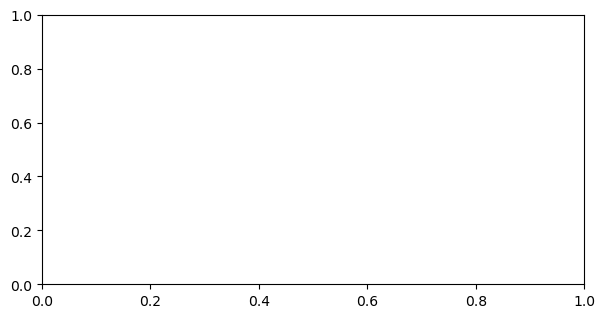

In [16]:
# ZADATAK 6 — rešenje (sve vrednosti su PRETPOSTAVKE, nisu TESS merenja)
G, M_E, R_E = 6.674e-11, 5.972e24, 6.371e6          # SI
AU, M_SUN, L_SUN, GYR = 1.496e11, 1.989e30, 3.828e26, 3.156e16
M_ATM_EARTH, M_OCEAN = 5.15e18, 1.4e21               # kg (referentne vrednosti za poređenje)

# ---------- 1) Hipotetička planeta i zvezda ----------
M_p, R_p = 1.5 * M_E, 1.15 * R_E                     # super-Zemlja (R ~ M^0.27)
a, M_star = 0.1 * AU, 0.2 * M_SUN                    # hipotetička zvezda M-patuljak
dt = 1.0 * GYR                                       # konstantan fluks 1 Gyr (grubo, gornja procena)

# ---------- 2) Tri pretpostavljena XUV scenarija (NISU izmerena TESS-om) ----------
L_xuv = {"nizak": 1e-6 * L_SUN, "srednji": 1e-5 * L_SUN, "visok": 1e-4 * L_SUN}
F_xuv = {k: L / (4 * np.pi * a**2) for k, L in L_xuv.items()}      # W/m²

# ---------- 3) Pretpostavke modela i račun ----------
ETA, RXUV_FACTOR = 0.1, 1.2                          # efikasnost; R_XUV = 1.2·R_p
R_xuv = RXUV_FACTOR * R_p
xi = a * (M_p / (3 * M_star)) ** (1 / 3) / R_xuv     # R_Hill / R_XUV
K_tide = 1 - 3 / (2 * xi) + 1 / (2 * xi**3)          # plimni faktor (Erkaev et al. 2007)
print(f"R_Hill/R_XUV = {xi:.1f} → K_tide = {K_tide:.3f}")

def escape(F, eta=ETA, rx=R_xuv, K=K_tide):
    mdot = eta * np.pi * rx**3 * F / (G * M_p * K)   # kg/s
    return mdot, mdot * dt

rows = []
for lvl, F in F_xuv.items():
    for eta in (0.01, ETA, 0.3):                     # ---------- 4) osetljivost na η ----------
        mdot, dM = escape(F, eta=eta)
        rows.append(dict(scenario=lvl, F_XUV_W_m2=round(F, 3), eta=eta, Mdot_kg_s=mdot,
                         dM_kg=dM, dM_deo_mase_planete=dM / M_p,
                         dM_u_atm_Zemlje=dM / M_ATM_EARTH, dM_u_okeanima=dM / M_OCEAN))
res = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda x: f"{x:.3g}")
display(res)

# osetljivost na R_XUV (ΔM ∝ R_XUV³)
for fac in (1.0, 1.2, 1.5):
    _, dM = escape(F_xuv["srednji"], rx=fac * R_p)
    print(f"srednji XUV, η = {ETA}, R_XUV = {fac}·R_p → ΔM/M_p = {dM / M_p:.2e}")

fig, ax = plt.subplots(figsize=(7, 3.5))
for eta in (0.01, ETA, 0.3):
    s = res[res["eta"] == eta]
    ax.plot(s["F_XUV_W_m2"], s["dM_deo_mase_planete"], "o-", label=f"η = {eta}")
ax.set(xscale="log", yscale="log", xlabel="Pretpostavljeni F_XUV [W/m²]", ylabel="ΔM / M_p (1 Gyr)",
       title="Osetljivost ilustrativnog modela (pretpostavke)")
ax.legend(); ax.grid(alpha=0.25); plt.show()

# ---------- 5) ----------
print("\nOvo NIJE dokaz da posmatrana planeta gubi atmosferu: F_XUV, η, R_XUV, K_tide, masa planete i Δt "
      "su zadati scenariji, a TESS optička kriva ne daje XUV fluks.")

**Odgovori — Zadatak 6**

**Pretpostavke (nisu merenja):** planeta M_p = 1.5 M⊕, R_p = 1.15 R⊕; zvezda M = 0.2 M☉ na a = 0.1 AU; Δt = 1 Gyr uz konstantan fluks; η = 0.1 (osetljivost: 0.01 i 0.3); R_XUV = 1.2 R_p; K_tide ≈ 0.95 po Erkaevu (izračunato iz Hillovog radijusa). XUV scenariji: L_XUV = 10⁻⁶, 10⁻⁵, 10⁻⁴ L☉ (nizak/srednji/visok), što daje F_XUV ≈ 0.14, 1.4 i 14 W/m² na planeti — **ne izvode se iz TESS krive**.

**Osetljivost:** ΔM je linearno proporcionalan sa η i F_XUV, a kubno sa R_XUV, pa je neizvesnost modela veća od razlike između scenarija. Numeričke vrednosti: tabela u izlazu koda.

**Zašto to nije dokaz:** zadati XUV fluks, efikasnost i geometrija su pretpostavke, a TESS optička svetlosna kriva ne meri XUV zračenje niti stvarnu atmosferu planete.


### Zadatak 7

Napišite **150–250 reči**: Ako je planeta u nastanjivoj zoni, šta nam svetlosna kriva aktivne zvezde govori, a šta ne govori o nastanjivosti? Povežite periodičnost, flare kandidate, pretpostavljeno XUV okruženje i neizvesnosti atmosferskog bekstva. Eksplicitno razdvojite **merenja**, **interpretacije** i **pretpostavke**.

**Odgovor studenta:**

Položaj planete u nastanjivoj zoni znači samo da bi, uz pogodnu atmosferu, na površini mogla postojati tečna voda. Svetlosna kriva aktivne zvezde govori o okruženju te atmosfere, ali nastanjivost ne dokazuje.

**Merenja.** TESS daje relativni optički fluks u vremenu, sa greškama, zastavicama kvaliteta, prekidima i sistematskim efektima. Amplituda varijabilnosti, periodogram i pojedinačna povećanja sjaja ostaju na nivou optičke fotometrije.

**Interpretacije.** Najviši pik Lomb–Scargle periodograma je samo kandidat za rotacioni period dok se ne proveri pokrivenost ciklusa, harmonici (P/2, 2P), alijasi i ponovljivost u obe polovine serije. Flare kandidat zahteva više uzastopnih validnih kadenci i oblik brzog porasta i sporijeg pada, a i tada je potvrda nesigurna; odsustvo kandidata je takođe legitiman rezultat. Optička kriva ne daje XUV fluks.

**Pretpostavke.** XUV luminoznost, efikasnost η, R_XUV, K_tide, masa planete i trajanje u modelu bekstva zadati su scenariji. Rezultat je linearan po η i F_XUV, a kubni po R_XUV, pa neizvesnost obuhvata više redova veličine. Izračunati gubitak mase ilustruje osetljivost modela i nije dokaz da planeta gubi atmosferu. Magnetno polje, sastav atmosfere i vulkansko dopunjavanje nisu uključeni.

Zaključak: kriva pokazuje koliko je zvezda aktivna, ali za nastanjivost su potrebni atmosfera, XUV istorija i planetni parametri koje ovde ne merimo.


## Reference i korisni linkovi

- [Lightkurve dokumentacija](https://lightkurve.github.io/lightkurve/)
- [MAST arhiva](https://mast.stsci.edu/)
- [TESS misija (NASA)](https://science.nasa.gov/mission/tess/)
- [Lightkurve — izbor quality bitmaske](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.SearchResult.download.html)
- [Astropy Lomb–Scargle](https://docs.astropy.org/en/stable/timeseries/lombscargle.html)

